In [1]:
import numpy as np
import math
from pathlib import Path

%matplotlib widget
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from scripts.utility_functions import (
    sort_point,
    Conv_coordinates,
    cartesian_to_polar,
    Calc_G,
    d_n,
    Calc_L
)

from scripts.task2_Dipole_Loc import plot_sphere, visualize_dipole
from scripts.task3_Unit_Vect import plot_hemisphere, visualize_sensors_unit_vectors

(33,)


In [2]:
data_dir = Path.cwd() / "data"

# Load the coordinate data files for dipoles, sensors and unit vectors
data1 = np.load(data_dir/"Dipole_coordinates.npz")
data2 = np.load(data_dir/"sensor_coordinates.npz")
data3 = np.load(data_dir/"Unit_Vect_coordinates.npz")

data4 = np.load(data_dir/"MEG_Lead_Field.npz")
data5 = np.load(data_dir/"EEG_Lead_Field.npz")

data6 = np.load(data_dir/"MEG_Measurements.npz")
data7 = np.load(data_dir/"EEG_Measurements.npz")

G = data4['G']
L = data5['L']

B_r = data6['B_r']
V = data7['V']


# Extract and organize dipole coordinates into array
rq_x = data1['x']
rq_y = data1['y']
rq_z = data1['z']
rq = np.stack((rq_x, rq_y, rq_z), axis=1)
r_d, theta_d, phi_d = cartesian_to_polar(rq_x, rq_y, rq_z)

# Define the orientation vector for the diapole
q_0 = np.array([0, 0, 1])

# Extract and organize sensor coordinates into array
r_x = data2['x']
r_y = data2['y']
r_z = data2['z']
r = np.stack((r_x, r_y, r_z), axis=1) 
r_s, theta_s, phi_s = cartesian_to_polar(r_x, r_y, r_z)

# Extract and organize unit vectors into array
er_x = data3['ex']
er_y = data3['ey']
er_z = data3['ez']
er = np.stack((er_x, er_y, er_z), axis=1) 

In [4]:
rank_G = np.linalg.matrix_rank(G)
print("Shape of G = ", G.shape)
print("Rank of G = ", rank_G)
print("Shape of B_r = ", B_r.shape)

rank_L = np.linalg.matrix_rank(L)
print("Shape of V = ", V.shape)
print("Rank of V = ", rank_L)
print("Shape of V = ", V.shape)

Shape of G =  (33, 315)
Rank of G =  33
Shape of B_r =  (33,)
Shape of V =  (33,)
Rank of V =  33
Shape of V =  (33,)


In [5]:
# --------------------------- calculate Current_source_vector ------------------------
# Calculate the current source vector using the minimum norm solution
q = G.T @ np.linalg.inv(G @ G.T) @ B_r

print("Shape of q = ", q.shape)
print("Estimated position of the source q = ", q)

# Initialize an array to store the magnitude of each current source

norm_q = np.zeros(105)

# Calculate the magnitude of each current source

for i in range(0, 105):
    norm_q[i] = np.linalg.norm(q[3 * i:3 * (i + 1)])
    
# Reshape the current source vector for easier analysis

q1 = q.reshape(105, 3)

# Print the estimated diapole orientation and related information
# print("q_0 vector = ", q1[104, :])
# print("diapole number = ", np.argmax(norm_q), "\nmaximum norm_q = ",
#       np.max(norm_q), "\nq_0 norm = ", norm_q[104])

print("q_0 vector = ", q1[104, :])
print("diapole number = ", np.argmax(norm_q), "\nmaximum norm_q = ",
      np.max(norm_q), "\nq_0 norm = ", norm_q[104])

Shape of q =  (315,)
Estimated position of the source q =  [-4.98810608e-03 -8.36418868e-03 -1.36285932e-05 -6.09106493e-03
 -7.43436071e-03  3.06046207e-04 -6.16071352e-03 -5.49148705e-03
  6.42746072e-04  1.79399886e-03  1.50714330e-03  2.05438003e-04
  1.89718397e-03  1.43387722e-03  1.14705945e-04  1.74172535e-03
  1.38645862e-03 -1.91222080e-04 -3.53667928e-03 -1.06363293e-02
 -3.25028821e-04  1.72855466e-03  1.56590300e-03  2.37721887e-04
  1.77476525e-03  1.56916977e-03  3.06740811e-04 -3.53171572e-03
 -1.08215157e-02 -4.98207351e-04 -9.40653061e-03 -1.29625585e-02
  8.83364451e-05 -1.11261755e-02 -1.30781478e-02  1.33608012e-03
 -1.12128240e-02 -1.50862469e-02  7.81622039e-04 -4.32704594e-03
 -2.67883614e-03  5.68952802e-04  1.92488256e-03  1.55212599e-03
  4.79982047e-04  1.80818641e-03  1.62439757e-03  4.56168062e-04
 -3.22410314e-03 -1.05665858e-02 -1.35381926e-03  2.06772001e-03
  1.47811165e-03  4.74486590e-04 -1.25464215e-02 -2.22681818e-02
  4.03970652e-03  1.47787263e-0

In [6]:
#  --------------------------- Calculate the relative error --------------------------
# Calculate the relative error between estimated and true diapole orientation

relative_q0_error = np.linalg.norm(q1[104, :] - q_0) / np.linalg.norm(q_0)
print('The relative q0 error =', relative_q0_error)

#TODO: Calculate the relative error across all estimated sources
# relative_q_error = ...
# print('The relative q error =', relative_q_error)

q_true = np.zeros_like(q1)
q_true[104] = q_0
relative_q_error = np.linalg.norm(q1 - q_true) / np.linalg.norm(q_true)
print('The relative q error =', relative_q_error)

The relative q0 error = 0.9465080863832463
The relative q error = 0.9720601572553974


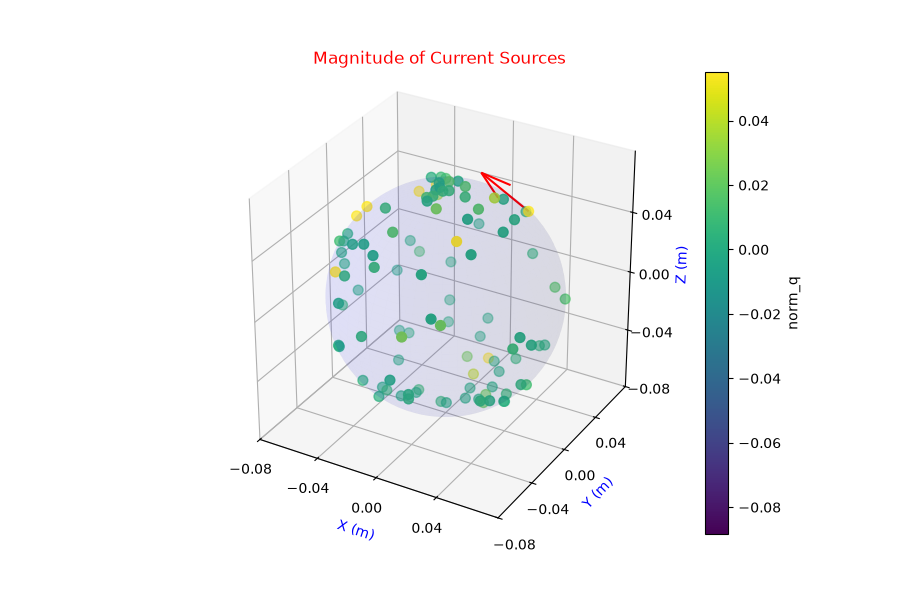

In [8]:
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
plt.title('Magnitude of Current Sources', c='r')

# Set size of each axis
ax.set_box_aspect([1, 1, 1])  # This will make the axes equally spaced
ax.set_xlim([-0.08, 0.08])
ax.set_ylim([-0.08, 0.08])
ax.set_zlim([-0.08, 0.08])

# Set the grid grading for each axis
ax.set_xticks(np.arange(-0.08, 0.08, 0.04))
ax.set_yticks(np.arange(-0.08, 0.08, 0.04))
ax.set_zticks(np.arange(-0.08, 0.08, 0.04))

q_min = np.min(q)
q_max = np.max(q)

# Plotting scatter with actual values
scatter = ax.scatter(rq_x, rq_y, rq_z, c=norm_q, cmap='viridis',
                     s=50, vmin=q_min, vmax=q_max)

# Adding color bar
cbar = plt.colorbar(scatter, pad=0.05)
cbar.set_label('norm_q')


ax.quiver(rq[104, 0], rq[104, 1], rq[104, 2], q1[104, 0], q1[104, 1], q1[104, 2], color='r', length=0.04,
          normalize=True, arrow_length_ratio=0.5)


radius = 0.07
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 100)

x_hemisphere = radius * np.outer(np.cos(u), np.sin(v))
y_hemisphere = radius * np.outer(np.sin(u), np.sin(v))
z_hemisphere = radius * np.outer(np.ones(np.size(u)), np.cos(v))

ax.plot_surface(x_hemisphere, y_hemisphere,
                z_hemisphere, color='b', alpha=0.05)

ax.set_xlabel('X (m)', c='b')
ax.set_ylabel('Y (m)', c='b')
ax.set_zlabel('Z (m)', c='b')

plt.show()